In [12]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import shutil
from io import BytesIO
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.optimizers import Adam
print("done")

done


In [5]:
from PIL import ImageFile

# Allow loading of truncated images in PIL.
# This can be useful when dealing with incomplete image files.

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [9]:
data_path = r"E:\SIC_AI\final_project\archive (2)\RGB ArSL dataset"
data = []   # List to store image data
labels = []  # List to store labels
categories = os.listdir(data_path) # List of categories in this dataset
for category in categories:
    category_path = os.path.join(data_path, category) # Full path to the category directory
    # Loop over each image in the category
    for img_name in os.listdir(category_path):
        img_path = os.path.join(category_path, img_name) # Full path to the image file
        img = load_img(img_path, target_size=(224, 224))  # Load and resize the image
        img_array = img_to_array(img) # Convert image to a NumPy array
        img_array /= 255.0  # Normalize pixel values to [0,1]
        data.append(img_array)  # Add image array to the data list
        # Add category (label) to the labels list
        labels.append(category)

label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(labels)
categorical_labels = to_categorical(encoded_labels)

In [10]:
# 1. General dataset information
print(f"Total loaded images: {len(data)}")
print(f"Total labels: {len(labels)}")
print(f"Number of categories (classes): {len(categories)}")
print(f"Class names: {label_encoder.classes_}\n")

# 2. Check single image dimensions and pixel value range (Normalization Check)
sample_img = data[0]
print(f"Single image shape after resizing: {sample_img.shape}")
print(f"Min pixel value (should be >= 0.0): {sample_img.min():.2f}")
print(f"Max pixel value (should be <= 1.0): {sample_img.max():.2f}\n")

# 3. Check encoding results (Label Encoding & One-Hot Encoding) for the first image
print(f"Original text label: {labels[0]}")
print(f"After LabelEncoder (integer): {encoded_labels[0]}")
print(f"After to_categorical (One-Hot Vector):\n{categorical_labels[0]}")
print(f"Final categorical_labels shape: {categorical_labels.shape}")

Total loaded images: 7856
Total labels: 7856
Number of categories (classes): 31
Class names: ['Ain' 'Al' 'Alef' 'Beh' 'Dad' 'Dal' 'Feh' 'Ghain' 'Hah' 'Heh' 'Jeem'
 'Kaf' 'Khah' 'Laa' 'Lam' 'Meem' 'Noon' 'Qaf' 'Reh' 'Sad' 'Seen' 'Sheen'
 'Tah' 'Teh' 'Teh_Marbuta' 'Thal' 'Theh' 'Waw' 'Yeh' 'Zah' 'Zain']

Single image shape after resizing: (224, 224, 3)
Min pixel value (should be >= 0.0): 0.00
Max pixel value (should be <= 1.0): 0.81

Original text label: Ain
After LabelEncoder (integer): 0
After to_categorical (One-Hot Vector):
[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0.]
Final categorical_labels shape: (7856, 31)


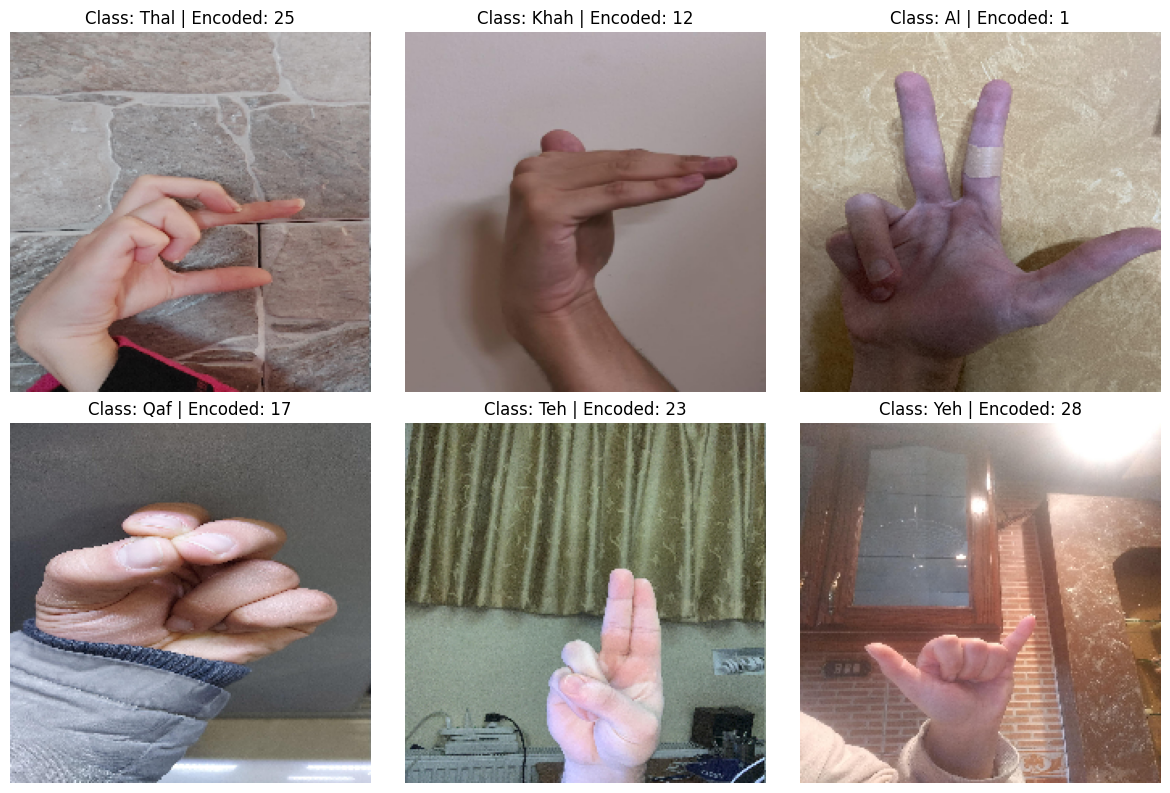

In [11]:
import random

# Display 6 random preprocessed images
plt.figure(figsize=(12, 8))

for i in range(6):
    idx = random.randint(0, len(data) - 1)
    plt.subplot(2, 3, i + 1)
    
    # Display image array (values between 0 and 1 are rendered normally by matplotlib)
    plt.imshow(data[idx])
    plt.title(f"Class: {labels[idx]} | Encoded: {encoded_labels[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

C:\Users\osama Aboud\AppData\Local\Temp\ipykernel_29736\3926048194.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=labels, order=label_encoder.classes_, palette="viridis")


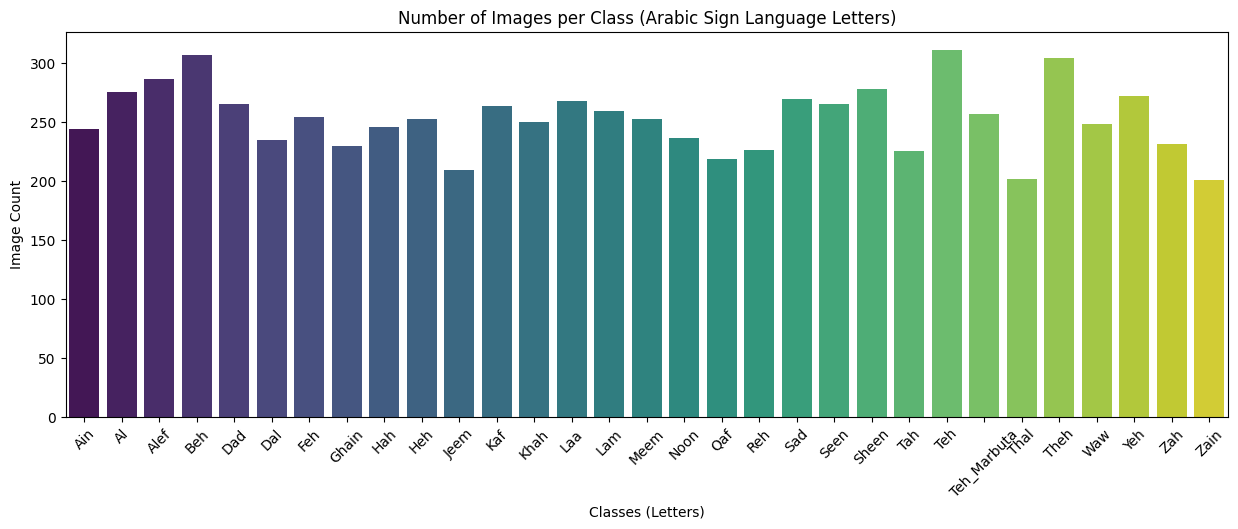

In [13]:
# check data balance
plt.figure(figsize=(15, 5))
sns.countplot(x=labels, order=label_encoder.classes_, palette="viridis")
plt.title("Number of Images per Class (Arabic Sign Language Letters)")
plt.xlabel("Classes (Letters)")
plt.ylabel("Image Count")
plt.xticks(rotation=45)
plt.show()

In [14]:
label_encoder = LabelEncoder()
encoded_label = label_encoder.fit_transform(labels)
categorical_labels = to_categorical(encoded_label)
X_train, X_test, y_train, y_test = train_test_split(data, categorical_labels, test_size=0.2, random_state=42)
X_test,X_val,y_test,y_val=train_test_split(X_test,y_test,test_size=0.5, random_state=42)
X_train = np.array(X_train)
X_val = np.array(X_val)
X_test = np.array(X_test)
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)
print(f'X_train shape is {X_train.shape}')
print(f'X_val shape is {X_val.shape}')
print(f'X_test shape is {X_test.shape}')
print(f'y_train shape is {y_train.shape}')
print(f'y_val shape is {y_val.shape}')
print(f'y_test shape is {y_test.shape}')

X_train shape is (6284, 224, 224, 3)
X_val shape is (786, 224, 224, 3)
X_test shape is (786, 224, 224, 3)
y_train shape is (6284, 31)
y_val shape is (786, 31)
y_test shape is (786, 31)
